# Assignment 17: Feature Selection for Classification
**Modern AI (AI26501)** | Group 14 | Dataset: Breast Cancer Wisconsin (Diagnostic)

**Research question:** Can ANOVA F-test feature selection (`SelectKBest`) reduce input dimensionality and computational cost while maintaining classification performance?

- **H1 (efficiency):** fewer features may reduce Logistic Regression training and inference time.
- **H2 (performance):** a smaller subset may keep Accuracy and Macro-F1 close to the baseline.

**Improvements over the first version**
1. Timings are the **median of many repeats** (a single timing was too noisy to support H1).
2. Added **confusion matrices** and **malignant-missed (false negative)** counts.
3. Added **repeated stratified 5-fold CV** with a leak-free `Pipeline`, because the 114-sample test set changes by 0.88 points per error.
4. Selected **feature names** are reported for every k.
5. Figures are saved **before** `plt.show()` (previously a blank figure was saved).
6. All settings are in one config cell; the notebook is reproducible end to end.

In [1]:
# 1. IMPORTS AND CONFIGURATION
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline

SEED = 42
TEST_SIZE = 0.20
K_VALUES = [20, 15, 10, 5]        # plus the all-features baseline
TIMING_REPEATS = 200              # repeats for median timing
CV_SPLITS, CV_REPEATS = 5, 10     # repeated stratified k-fold

OUT_DIR = Path("results")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load dataset

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset shape      :", X.shape)
print("Number of features :", X.shape[1])
print("Missing values     :", int(X.isna().sum().sum()))
print("\nClass distribution (0 = malignant, 1 = benign):")
print(y.map({0: "malignant", 1: "benign"}).value_counts())

Dataset shape      : (569, 30)
Number of features : 30
Missing values     : 0

Class distribution (0 = malignant, 1 = benign):
target
benign       357
malignant    212
Name: count, dtype: int64


## 3. Stratified train/test split (same split for every configuration)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Test class counts:", y_test.value_counts().to_dict())
print(f"One test error = {100 / len(y_test):.2f} percentage points of accuracy")

Training samples: 455
Testing samples : 114
Test class counts: {1: 72, 0: 42}
One test error = 0.88 percentage points of accuracy


## 4. Scaling
The scaler is fitted on the training data only. (The ANOVA F-test itself is scale-invariant, but Logistic Regression is not, so scaling still matters for the classifier.)

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaling completed.")

Scaling completed.


## 5. Experiment: all features vs Top-k
Each configuration reports test-set metrics from one fitted model. Training and inference times are the **median of `TIMING_REPEATS` runs** after a warm-up call. `Selection Transform (s)` is the extra time `SelectKBest.transform` needs at prediction time, which the first version ignored.

In [5]:
def median_time(fn, repeats=TIMING_REPEATS):
    fn()  # warm-up
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


def run_config(k=None):
    """k=None -> all features baseline."""
    if k is None:
        Xtr, Xte = X_train_scaled, X_test_scaled
        feats = list(X.columns)
        sel_time = 0.0
        name = "All features"
    else:
        selector = SelectKBest(score_func=f_classif, k=k).fit(X_train_scaled, y_train)
        Xtr, Xte = selector.transform(X_train_scaled), selector.transform(X_test_scaled)
        feats = list(X.columns[selector.get_support()])
        sel_time = median_time(lambda: selector.transform(X_test_scaled))
        name = f"Top-{k}"

    model = LogisticRegression(max_iter=5000, random_state=SEED).fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    train_t = median_time(lambda: LogisticRegression(max_iter=5000, random_state=SEED).fit(Xtr, y_train))
    infer_t = median_time(lambda: model.predict(Xte))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])  # rows: true, cols: predicted (0=malignant)
    row = {
        "Configuration": name,
        "Number of Features": len(feats),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro-F1": f1_score(y_test, y_pred, average="macro"),
        "Test Errors": int((y_test != y_pred).sum()),
        "Malignant Missed (FN)": int(cm[0, 1]),
        "Benign Flagged (FP)": int(cm[1, 0]),
        "Training Time (s)": train_t,
        "Inference Time (s)": infer_t,
        "Selection Transform (s)": sel_time,
    }
    return row, cm, feats


results, confusions, feature_sets = [], {}, {}
for k in [None] + K_VALUES:
    row, cm, feats = run_config(k)
    results.append(row)
    confusions[row["Configuration"]] = cm
    feature_sets[row["Configuration"]] = feats
    print("done:", row["Configuration"])

results_df = pd.DataFrame(results)

done: All features
done: Top-20
done: Top-15
done: Top-10
done: Top-5


## 6. Results table

In [6]:
display(
    results_df.style.format({
        "Accuracy": "{:.4f}", "Macro-F1": "{:.4f}",
        "Training Time (s)": "{:.6f}", "Inference Time (s)": "{:.6f}",
        "Selection Transform (s)": "{:.6f}",
    }).hide(axis="index")
)

base = results_df.iloc[0]
summary = results_df[["Configuration", "Number of Features"]].copy()
summary["Accuracy change vs baseline (pp)"] = (results_df["Accuracy"] - base["Accuracy"]) * 100
summary["Macro-F1 change vs baseline (pp)"] = (results_df["Macro-F1"] - base["Macro-F1"]) * 100
summary["Training time vs baseline"] = results_df["Training Time (s)"] / base["Training Time (s)"]
summary["Inference time vs baseline"] = results_df["Inference Time (s)"] / base["Inference Time (s)"]
display(summary.style.format({
    "Accuracy change vs baseline (pp)": "{:+.2f}",
    "Macro-F1 change vs baseline (pp)": "{:+.2f}",
    "Training time vs baseline": "{:.2f}x",
    "Inference time vs baseline": "{:.2f}x",
}).hide(axis="index"))

Configuration,Number of Features,Accuracy,Macro-F1,Test Errors,Malignant Missed (FN),Benign Flagged (FP),Training Time (s),Inference Time (s),Selection Transform (s)
All features,30,0.9825,0.9812,2,1,1,0.010991,0.000199,0.000000
Top-20,20,0.9737,0.9719,3,1,2,0.009217,0.000476,0.000176
Top-15,15,0.9649,0.9623,4,2,2,0.010073,0.000390,0.000493
Top-10,10,0.9474,0.9440,6,2,4,0.010555,0.000414,0.000401
Top-5,5,0.9386,0.9349,7,2,5,0.009188,0.000359,0.000372


Configuration,Number of Features,Accuracy change vs baseline (pp),Macro-F1 change vs baseline (pp),Training time vs baseline,Inference time vs baseline
All features,30,+0.00,+0.00,1.00x,1.00x
Top-20,20,-0.88,-0.93,0.84x,2.39x
Top-15,15,-1.75,-1.88,0.92x,1.96x
Top-10,10,-3.51,-3.72,0.96x,2.08x
Top-5,5,-4.39,-4.62,0.84x,1.80x


## 7. Confusion matrices
Class 0 = malignant, class 1 = benign. In a diagnostic task a **false negative** (malignant predicted as benign) is the costly error, so it is reported separately.

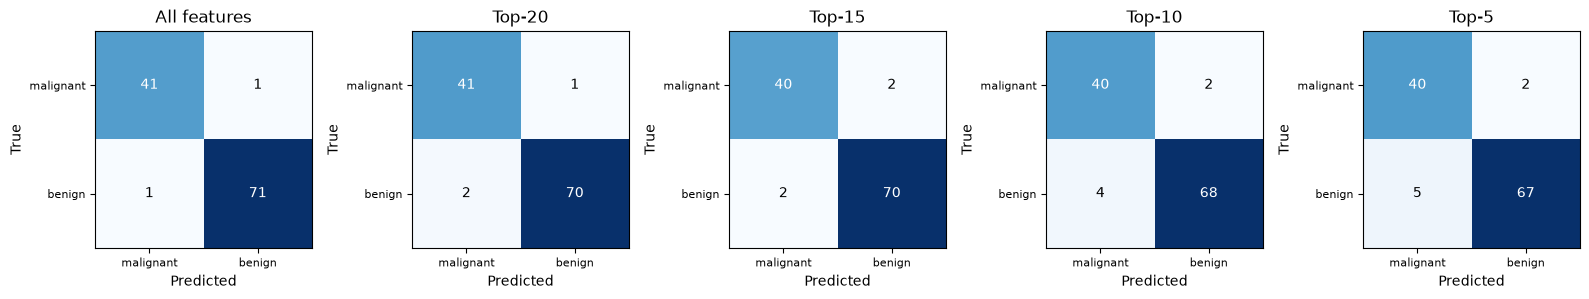

In [7]:
fig, axes = plt.subplots(1, len(confusions), figsize=(3.2 * len(confusions), 3.4))
for ax, (name, cm) in zip(axes, confusions.items()):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["malignant", "benign"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["malignant", "benign"], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Which features were selected?
`SelectKBest` ranks features by F-score, so smaller subsets are nested inside larger ones.

In [8]:
selector_all = SelectKBest(score_func=f_classif, k="all").fit(X_train_scaled, y_train)
feature_scores = (
    pd.DataFrame({"Feature": X.columns, "F-Score": selector_all.scores_})
    .sort_values("F-Score", ascending=False)
    .reset_index(drop=True)
)
feature_scores.index += 1
feature_scores.index.name = "Rank"
display(feature_scores.head(15))

for k in sorted(K_VALUES):
    print(f"\nTop-{k} features:")
    print(", ".join(feature_sets[f"Top-{k}"]))

top10 = feature_sets["Top-10"]
size_related = [f for f in top10 if any(w in f for w in ("radius", "perimeter", "area"))]
print(f"\n{len(size_related)} of the Top-10 are radius/perimeter/area features, which are strongly "
      "correlated with each other. A univariate filter does not remove this redundancy.")

,Feature,F-Score
Rank,,
1,worst concave points,795.223341
2,worst perimeter,719.598823
3,mean concave points,703.364031
4,worst radius,687.430367
5,mean perimeter,565.485755
6,worst area,541.713694
7,mean radius,523.613907
8,mean area,469.516453
9,mean concavity,416.374874



Top-5 features:
mean perimeter, mean concave points, worst radius, worst perimeter, worst concave points

Top-10 features:
mean radius, mean perimeter, mean area, mean concavity, mean concave points, worst radius, worst perimeter, worst area, worst concavity, worst concave points

Top-15 features:
mean radius, mean perimeter, mean area, mean compactness, mean concavity, mean concave points, radius error, perimeter error, area error, worst radius, worst perimeter, worst area, worst compactness, worst concavity, worst concave points

Top-20 features:
mean radius, mean texture, mean perimeter, mean area, mean compactness, mean concavity, mean concave points, radius error, perimeter error, area error, concave points error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry

6 of the Top-10 are radius/perimeter/area features, which are strongly correlated with each other. A univariate filter d

## 9. Cross-validated comparison (leak-free pipeline)
A single 114-sample test set is a noisy estimate. Here the scaler, selector and classifier are wrapped in a `Pipeline`, so every fold fits them on its own training portion only.

In [9]:
cv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
cv_rows = []
for k in [None] + K_VALUES:
    steps = [("scale", StandardScaler())]
    if k is not None:
        steps.append(("select", SelectKBest(f_classif, k=k)))
    steps.append(("clf", LogisticRegression(max_iter=5000, random_state=SEED)))
    scores = cross_validate(Pipeline(steps), X, y, cv=cv,
                            scoring={"acc": "accuracy", "f1": "f1_macro"})
    cv_rows.append({
        "Configuration": "All features" if k is None else f"Top-{k}",
        "Number of Features": X.shape[1] if k is None else k,
        "CV Accuracy (mean)": scores["test_acc"].mean(),
        "CV Accuracy (std)": scores["test_acc"].std(),
        "CV Macro-F1 (mean)": scores["test_f1"].mean(),
        "CV Macro-F1 (std)": scores["test_f1"].std(),
    })

cv_df = pd.DataFrame(cv_rows)
display(cv_df.style.format({c: "{:.4f}" for c in cv_df.columns if c.startswith("CV")}).hide(axis="index"))
print(f"{CV_SPLITS}-fold x {CV_REPEATS} repeats = {CV_SPLITS * CV_REPEATS} folds per configuration")

Configuration,Number of Features,CV Accuracy (mean),CV Accuracy (std),CV Macro-F1 (mean),CV Macro-F1 (std)
All features,30,0.9789,0.0142,0.9772,0.0154
Top-20,20,0.9775,0.0151,0.9757,0.0165
Top-15,15,0.9496,0.0186,0.9458,0.0202
Top-10,10,0.9534,0.0203,0.9499,0.0220
Top-5,5,0.9439,0.0207,0.9396,0.0225


5-fold x 10 repeats = 50 folds per configuration


## 10. Figures (each is saved before `plt.show()`)

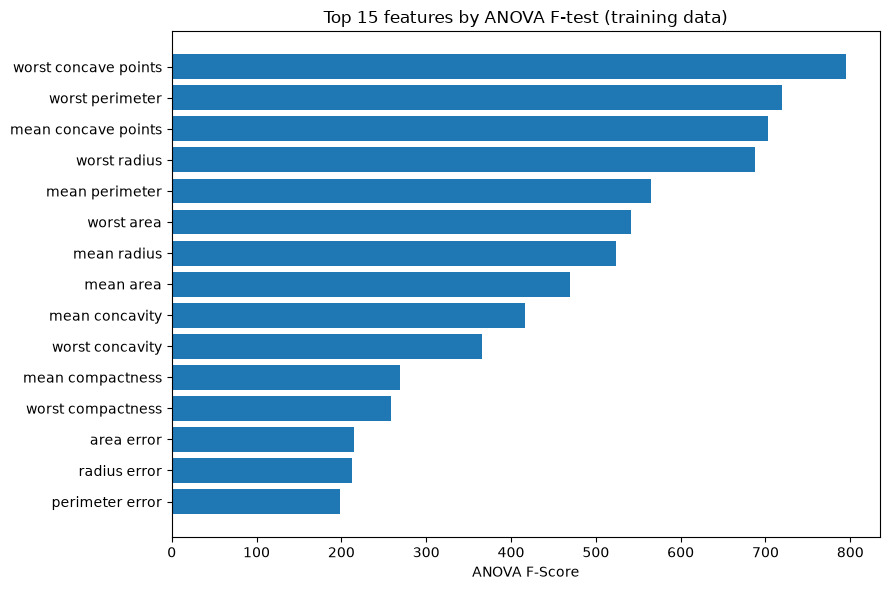

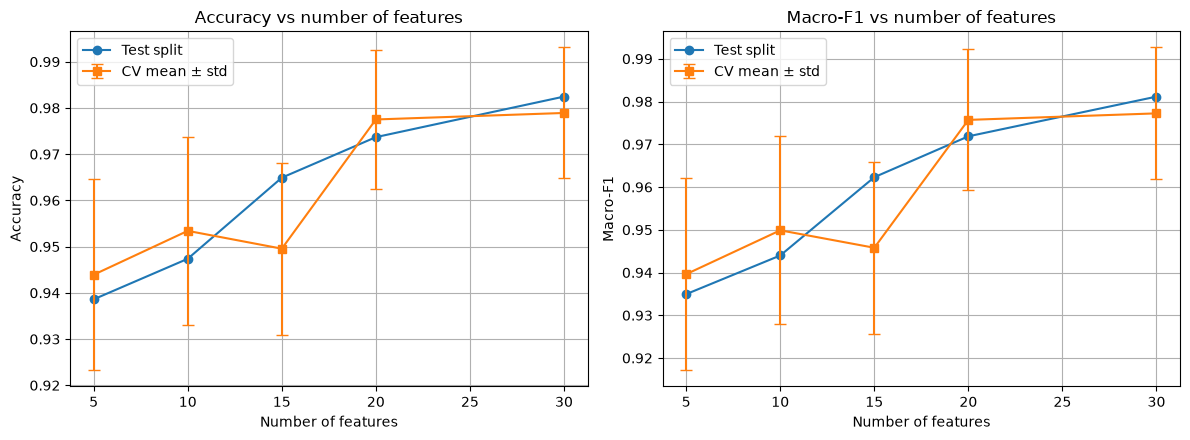

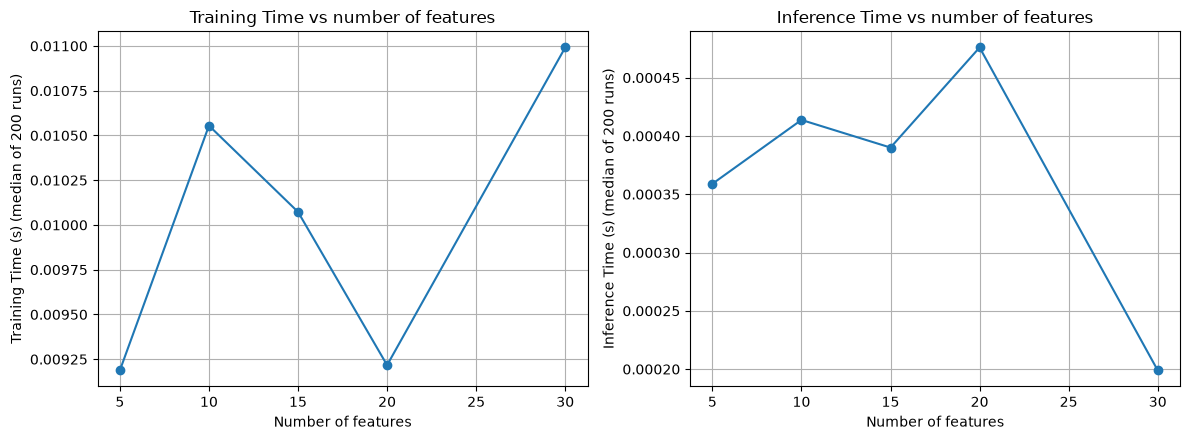

In [10]:
plot_df = results_df.sort_values("Number of Features")
cv_plot = cv_df.sort_values("Number of Features")

# 10a. Top-15 F-scores
top15 = feature_scores.head(15)
plt.figure(figsize=(9, 6))
plt.barh(top15["Feature"][::-1], top15["F-Score"][::-1])
plt.xlabel("ANOVA F-Score"); plt.title("Top 15 features by ANOVA F-test (training data)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_f_scores.png", dpi=300, bbox_inches="tight")
plt.show()

# 10b. Accuracy and Macro-F1 vs number of features (test split and CV)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, cv_metric in zip(axes, ["Accuracy", "Macro-F1"], ["CV Accuracy", "CV Macro-F1"]):
    ax.plot(plot_df["Number of Features"], plot_df[metric], marker="o", label="Test split")
    ax.errorbar(cv_plot["Number of Features"], cv_plot[f"{cv_metric} (mean)"],
                yerr=cv_plot[f"{cv_metric} (std)"], marker="s", capsize=4, label="CV mean ± std")
    ax.set_xlabel("Number of features"); ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs number of features"); ax.grid(True); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "performance_vs_features.png", dpi=300, bbox_inches="tight")
plt.show()

# 10c. Training and inference time vs number of features (median)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ["Training Time (s)", "Inference Time (s)"]):
    ax.plot(plot_df["Number of Features"], plot_df[col], marker="o")
    ax.set_xlabel("Number of features"); ax.set_ylabel(f"{col} (median of {TIMING_REPEATS} runs)")
    ax.set_title(f"{col.replace(' (s)', '')} vs number of features"); ax.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "time_vs_features.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Save results

In [11]:
results_df.to_csv(OUT_DIR / "results.csv", index=False)
cv_df.to_csv(OUT_DIR / "cv_results.csv", index=False)
feature_scores.to_csv(OUT_DIR / "feature_scores.csv")
pd.DataFrame({k: pd.Series(v) for k, v in feature_sets.items()}).to_csv(OUT_DIR / "selected_features.csv", index=False)
print("Saved to", OUT_DIR.resolve())
print(sorted(p.name for p in OUT_DIR.rglob("*") if p.is_file()))

Saved to E:\Code\Python\ASSIGNMENT 17\results
['confusion_matrices.png', 'cv_results.csv', 'feature_f_scores.png', 'feature_scores.csv', 'performance_vs_features.png', 'results.csv', 'selected_features.csv', 'time_vs_features.png']


## 12. Summary of findings (computed from the results above)

In [12]:
b = results_df.iloc[0]
print(f"Baseline (30 features): accuracy {b['Accuracy']:.4f}, Macro-F1 {b['Macro-F1']:.4f}, "
      f"{b['Test Errors']} errors on {len(y_test)} test samples\n")

print("H2 (predictive performance)")
for _, r in results_df.iloc[1:].iterrows():
    cvr = cv_df[cv_df["Configuration"] == r["Configuration"]].iloc[0]
    cvb = cv_df.iloc[0]
    print(f"  {r['Configuration']:7s}: test acc {100*(r['Accuracy']-b['Accuracy']):+.2f} pp "
          f"({r['Test Errors']} errors, {r['Malignant Missed (FN)']} malignant missed) | "
          f"CV acc {100*(cvr['CV Accuracy (mean)']-cvb['CV Accuracy (mean)']):+.2f} pp")

print("\nH1 (efficiency): median training / inference time relative to baseline")
for _, r in results_df.iloc[1:].iterrows():
    print(f"  {r['Configuration']:7s}: train {r['Training Time (s)']/b['Training Time (s)']:.2f}x, "
          f"inference {r['Inference Time (s)']/b['Inference Time (s)']:.2f}x")

print("\nLimitations: one dataset, one classifier, a univariate filter that ignores feature redundancy, "
      "and millisecond-scale timings that depend on the machine.")

Baseline (30 features): accuracy 0.9825, Macro-F1 0.9812, 2 errors on 114 test samples

H2 (predictive performance)
  Top-20 : test acc -0.88 pp (3 errors, 1 malignant missed) | CV acc -0.14 pp
  Top-15 : test acc -1.75 pp (4 errors, 2 malignant missed) | CV acc -2.94 pp
  Top-10 : test acc -3.51 pp (6 errors, 2 malignant missed) | CV acc -2.55 pp
  Top-5  : test acc -4.39 pp (7 errors, 2 malignant missed) | CV acc -3.50 pp

H1 (efficiency): median training / inference time relative to baseline
  Top-20 : train 0.84x, inference 2.39x
  Top-15 : train 0.92x, inference 1.96x
  Top-10 : train 0.96x, inference 2.08x
  Top-5  : train 0.84x, inference 1.80x

Limitations: one dataset, one classifier, a univariate filter that ignores feature redundancy, and millisecond-scale timings that depend on the machine.
